# Datos: ETL y análisis exploratorio

Este capítulo reconstruye el ETL del Entregable 1 como un módulo reproducible
(`src/etl.py`, `src/features.py`) e incorpora las tres correcciones solicitadas: el periodo
de modelado comienza cuando toda la red de estaciones está instalada, los intervalos de
confianza se obtienen con bootstrap por bloques y el parámetro de regularización del modelo
base se ajusta por validación cruzada cronológica. El análisis exploratorio se amplía con el
estudio del mecanismo de los faltantes que subsisten tras el recorte, la deriva entre
periodos y la sensibilidad del desempeño a la estrategia de imputación.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
from myst_nb import glue
from src import estilo
from src.config import DATOS_PROC, FECHA_CORTE_TEST, INICIO_MODELADO, SEED, NOMBRES_LEGIBLES, fijar_semillas
from src.estilo import RIO, SED, CAU, ALE, NEU
fijar_semillas()
caudales = pd.read_csv(DATOS_PROC / "caudales.csv", parse_dates=["fecha"])
par = json.loads((DATOS_PROC / "parametros.json").read_text(encoding="utf-8"))["calamar"]
tarea = pd.read_parquet(DATOS_PROC / "tarea_calamar.parquet")
EST = [e for e in caudales.columns if e != "fecha"]
NL = NOMBRES_LEGIBLES

## Fuente, estructura y ETL

Los datos provienen del portal DHIME del IDEAM {cite}`ideam2026` y corresponden a series de
caudal medio diario y de transporte medio diario de sedimentos en suspensión de siete
estaciones del cauce principal del Magdalena. La unidad de observación es el día en una
estación; el conjunto es un panel temporal corto en entidades (siete) y largo en tiempo, de
modo que su tamaño efectivo depende sobre todo de la autocorrelación y no del número de
filas. La licencia del portal autoriza la descarga para uso personal y no comercial, por lo
que el repositorio documenta el procedimiento de descarga y no redistribuye los archivos
originales.

In [2]:
filas = []
for e in EST:
    s = caudales.set_index("fecha")[e]
    filas.append({"Estación": NL[e], "Inicio": s.first_valid_index().date(), "Fin": s.last_valid_index().date(),
                  "Faltantes 1940-2026 (%)": round(100 * s.isna().mean(), 1),
                  "Faltantes desde 1947 (%)": round(100 * s["1947":].isna().mean(), 1),
                  "Faltantes desde 1976 (%)": round(100 * s["1976":].isna().mean(), 1),
                  "Media (m³/s)": round(s.mean()), "Asimetría": round(s.skew(), 2)})
inv = pd.DataFrame(filas)
glue("n_dias", len(caudales), display=False)
inv

,Estación,Inicio,Fin,Faltantes 1940-2026 (%),Faltantes desde 1947 (%),Faltantes desde 1976 (%),Media (m³/s),Asimetría
0,Arrancaplumas,1940-07-23,2014-12-31,18.3,15.6,23.4,1298,1.27
1,Calamar,1940-07-23,2026-09-24,1.6,1.2,0.5,7221,0.27
2,Coyongal,1975-03-01,2026-09-04,47.9,43.7,11.9,4988,-0.05
3,El Banco,1972-10-01,2026-09-24,39.6,34.7,3.0,4117,0.55
4,Puerto Salgar,1946-01-01,2026-09-24,9.8,3.8,2.5,1582,1.20
5,San Roque,1972-10-01,2025-09-13,40.4,35.6,4.9,498,0.69
6,Tres Cruces,1974-10-01,2026-08-31,46.7,42.3,11.9,2330,0.22


El ETL lee los catorce archivos, corrige la marca de orden de bytes y los metadatos
repetidos en cada fila, unifica los nombres de las estaciones y construye una tabla ancha
sobre el calendario diario de Calamar, con {glue:text}`n_dias:,` días entre 1940 y 2026. Los
días sin registro quedan como valores faltantes explícitos; ninguna serie se rellena en esta
etapa.

## Corrección 1: periodo de modelado y mecanismo de los faltantes

La retroalimentación del Entregable 1 señaló que la imputación por mediana de estaciones que
aún no existían carecía de justificación. La observación es correcta y su alcance era mayor
de lo que el informe original reconocía: entre el 40 % y el 48 % de los valores de El Banco,
San Roque, Tres Cruces y Coyongal eran medianas asignadas a años anteriores a su instalación.
Ese faltante no es aleatorio en ningún sentido útil, porque depende de forma determinista de
la fecha, y la mediana impuesta convertía cuatro predictores en constantes durante tres
décadas del entrenamiento, mientras la prueba (2010-2026) se evaluaba con valores reales.

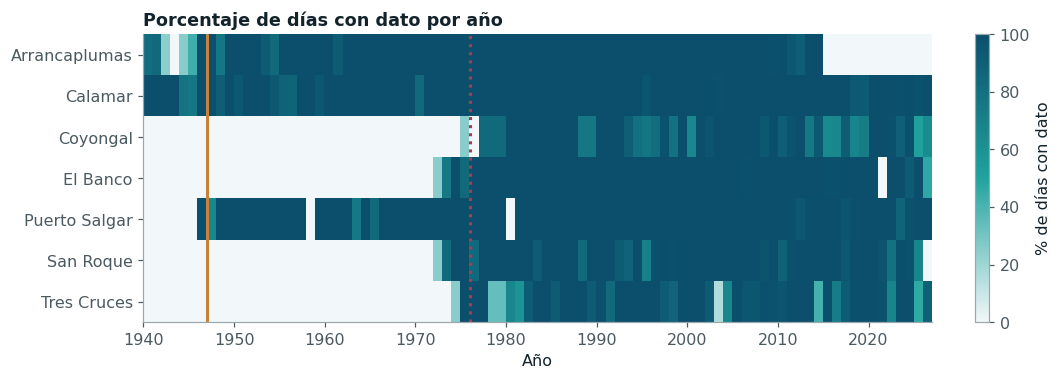

In [3]:
cob = caudales.set_index("fecha")[EST].notna().resample("YS").mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.4))
im = ax.imshow(cob.T, aspect="auto", cmap=estilo.mapa_seq(), vmin=0, vmax=100,
               extent=[cob.index.year.min(), cob.index.year.max() + 1, len(EST), 0])
ax.set_yticks(np.arange(len(EST)) + .5, [NL[e] for e in EST]); ax.grid(False)
ax.axvline(1947, color=SED, lw=2); ax.axvline(1976, color=ALE, ls=":", lw=2)
ax.set_xlabel("Año"); ax.set_title("Porcentaje de días con dato por año")
fig.colorbar(im, ax=ax, label="% de días con dato", fraction=.025)
plt.show()

Había dos formas de eliminar la imputación de estaciones inexistentes, y ambas se evaluaron.
La primera conserva las seis estaciones y recorta el periodo de modelado a 1976, cuando la
última estación de la red (Coyongal, marzo de 1975) acumula un año de registro. La segunda
conserva el periodo largo y restringe los predictores a las estaciones que existen durante
todo él: Calamar, la estación objetivo, y Puerto Salgar, con registro desde 1946, de modo que
el modelado empieza el 1 de enero de 1947. La guía del curso fija además un mínimo de 20.000
observaciones. La tabla siguiente compara los tres diseños (el del Entregable 1 y las dos
alternativas) con los mismos modelos de referencia evaluados en la prueba reservada.

In [4]:
from src.features import construir_tarea
from src.splits import separar_prueba
from sklearn.metrics import average_precision_score
from xgboost import XGBClassifier
from src.models import construir_pipeline
disenos = {
    "Entregable 1: seis estaciones desde 1940, imputadas": (["coyongal", "el_banco", "pto_salgar", "san_roque", "tres_cruces"], "1940-01-01"),
    "Alternativa: seis estaciones desde 1976": (["coyongal", "el_banco", "pto_salgar", "san_roque", "tres_cruces"], "1976-01-01"),
    "Adoptado: Calamar y Puerto Salgar desde 1947": (["pto_salgar"], "1947-01-01"),
}
filas = []
for nombre, (pred, ini) in disenos.items():
    t = construir_tarea(caudales, "calamar", pred, par["TRANSITOS"], par["Q_EF"], tuple(par["LIM"]), inicio=ini)
    d, cs = t["datos"], t["columnas"]
    a_, b_ = separar_prueba(d.fecha)
    ytr_, yte_ = d.y.iloc[a_].astype(int), d.y.iloc[b_].astype(int)
    xg = XGBClassifier(n_estimators=300, max_depth=4, learning_rate=.05, n_jobs=4, random_state=SEED).fit(d.iloc[a_][cs], ytr_)
    lr = construir_pipeline("clf", "logistica", {"C": 0.1, "penalty": "l1"}, "balanced").fit(d.iloc[a_][cs], ytr_)
    est_cols = [c for c in cs if not c.startswith(("calamar", "sen", "cos", "dist"))]
    filas.append({"diseño": nombre, "observaciones": len(d), "entrenamiento": len(a_), "prueba": len(b_), "predictores": len(cs),
                  "faltantes en predictores de estaciones (%)": 100 * d.iloc[a_][est_cols].isna().mean().mean(),
                  "≥ 20.000": "sí" if len(d) >= 20000 else "no",
                  "PR-AUC XGBoost": average_precision_score(yte_, xg.predict_proba(d.iloc[b_][cs])[:, 1]),
                  "PR-AUC logística": average_precision_score(yte_, lr.predict_proba(d.iloc[b_][cs])[:, 1])})
dis = pd.DataFrame(filas).set_index("diseño")
for k, n in zip(("e1", "r76", "a47"), dis.index):
    glue(f"n_{k}", int(dis.loc[n, "observaciones"]), display=False)
    glue(f"xg_{k}", float(dis.loc[n, "PR-AUC XGBoost"]), display=False)
    glue(f"lr_{k}", float(dis.loc[n, "PR-AUC logística"]), display=False)
    glue(f"fe_{k}", float(dis.loc[n, "faltantes en predictores de estaciones (%)"]), display=False)
dis.round(3)

,observaciones,entrenamiento,prueba,predictores,faltantes en predictores de estaciones (%),≥ 20.000,PR-AUC XGBoost,PR-AUC logística
diseño,,,,,,,,
"Entregable 1: seis estaciones desde 1940, imputadas",30741,24765,5946,43,42.901,sí,0.940,0.875
Alternativa: seis estaciones desde 1976,18359,12383,5946,43,5.845,no,0.919,0.882
Adoptado: Calamar y Puerto Salgar desde 1947,28588,22612,5946,31,4.708,sí,0.941,0.880


El recorte a 1976 resuelve la imputación pero deja {glue:text}`n_r76:,` observaciones, por
debajo del mínimo de la guía. El diseño adoptado cumple ambas exigencias: no imputa ninguna
estación en años en que no existía y dispone de {glue:text}`n_a47:,` observaciones. La
comparación empírica lo respalda. Con XGBoost, la PR-AUC en la prueba es
{glue:text}`xg_a47:.3f` con Calamar y Puerto Salgar desde 1947, frente a {glue:text}`xg_r76:.3f`
con las seis estaciones desde 1976 y {glue:text}`xg_e1:.3f` con el diseño del Entregable 1; con
la regresión logística, menos sensible al tamaño de la muestra, los tres valores
({glue:text}`lr_a47:.3f`, {glue:text}`lr_r76:.3f` y {glue:text}`lr_e1:.3f`) difieren en menos de
una centésima. La lectura conjunta es clara: lo que da ventaja al modelo no lineal son los treinta
años adicionales de registro, que abarcan más ciclos de El Niño y La Niña, y no las estaciones
del bajo Magdalena. El diseño del Entregable 1 alcanzaba casi el mismo desempeño que el adoptado
porque también usaba el periodo largo, pero lo hacía alimentando cuatro predictores con medianas
durante tres décadas; el diseño adoptado obtiene el mismo resultado sin esa imputación. La
información anticipada de las estaciones del bajo Magdalena está en buena parte contenida en el
estado reciente de Calamar: la más informativa, Coyongal, tiene un tiempo de tránsito de siete
días, inferior al horizonte de predicción. Las seis estaciones no
se descartan del proyecto: intervienen en las tres tareas adicionales con las que se evalúa el
modelo original (capítulo 6), que empiezan en 1976. El análisis magnitud-frecuencia de la
descarga efectiva se mantiene sobre 1940-2009, porque solo usa la serie de Calamar.

In [5]:
inicio_op = {"pto_salgar": "1947-01-01", "arrancaplumas": "1947-01-01"}
filas = []
for e in EST:
    if e == "calamar":
        continue
    d_e = caudales[caudales.fecha >= inicio_op.get(e, "1976-01-01")]
    m = d_e[e].isna()
    a, b = d_e.loc[m, "calamar"].dropna(), d_e.loc[~m, "calamar"].dropna()
    if len(a) < 30:
        continue
    u = st.mannwhitneyu(a, b)
    rachas = (m.ne(m.shift()).cumsum()[m].value_counts())
    filas.append({"Estación": NL[e], "Periodo": "desde " + inicio_op.get(e, "1976-01-01")[:4], "Días sin dato": int(m.sum()),
                  "% sin dato": round(100 * m.mean(), 1), "Rachas": len(rachas),
                  "Racha mediana (d)": int(rachas.median()), "Racha máxima (d)": int(rachas.max()),
                  "Q Calamar sin dato (mediana)": round(a.median()), "Q Calamar con dato (mediana)": round(b.median()),
                  "A de Vargha-Delaney": round(u.statistic / (len(a) * len(b)), 3), "p": u.pvalue})
mec = pd.DataFrame(filas)
from src.stats_tests import holm
mec["p (Holm)"] = holm(mec.p.values)
d47 = caudales[caudales.fecha >= INICIO_MODELADO]
glue("a_ps", float(mec.set_index("Estación").loc["Puerto Salgar", "A de Vargha-Delaney"]), display=False)
glue("falt_ps", float(mec.set_index("Estación").loc["Puerto Salgar", "% sin dato"]), display=False)
glue("falt_cal", float(100 * d47.calamar.isna().mean()), display=False)
glue("a_coyongal", float(mec.set_index("Estación").loc["Coyongal", "A de Vargha-Delaney"]), display=False)
mec.style.format({"p": "{:.2g}", "p (Holm)": "{:.2g}"})

,Estación,Periodo,Días sin dato,% sin dato,Rachas,Racha mediana (d),Racha máxima (d),Q Calamar sin dato (mediana),Q Calamar con dato (mediana),A de Vargha-Delaney,p,p (Holm)
0,Arrancaplumas,desde 1947,4555,15.600000,15,29,4285,7087,7122,0.493000,0.15,0.31
1,Coyongal,desde 1976,2213,11.900000,82,6,425,5853,7259,0.346000,6.2e-120,3.7e-119
2,El Banco,desde 1976,552,3.000000,22,2,365,7984,7031,0.599000,2.1e-15,8.6e-15
3,Puerto Salgar,desde 1947,1111,3.800000,19,2,366,6190,7160,0.379000,1e-42,5e-42
4,San Roque,desde 1976,907,4.900000,33,9,376,7260,7057,0.513000,0.18,0.31
5,Tres Cruces,desde 1976,2198,11.900000,43,24,366,7080,7062,0.471000,8.3e-06,2.5e-05


Dentro de su periodo operativo, cada estación conserva huecos genuinos de operación. Para la
tarea principal importan los de Calamar ({glue:text}`falt_cal:.1f` % de los días desde 1947) y
los de Puerto Salgar ({glue:text}`falt_ps:.1f` %). Para establecer su mecanismo se comparó el
caudal de Calamar en los días con y sin registro de cada estación mediante la prueba de
Mann-Whitney y el tamaño de efecto A de Vargha y Delaney, con corrección de Holm. Con muestras de
este tamaño casi toda diferencia resulta significativa, de modo que la lectura se apoya en A: un
valor de 0,5 indica que la ausencia no se relaciona con el caudal. Puerto Salgar
(A = {glue:text}`a_ps:.3f`) y Coyongal (A = {glue:text}`a_coyongal:.3f`), esta última en las
tareas adicionales, tienen sus huecos concentrados en aguas bajas. El mecanismo es, por
tanto, MAR respecto del caudal observado en Calamar y no MCAR: la probabilidad de faltar depende
de una variable observada. De ese diagnóstico se siguen dos consecuencias: la imputación debe
ajustarse solo con el entrenamiento y dentro del pipeline, y su efecto sobre el desempeño debe
medirse, lo que se hace al final de este capítulo comparando la mediana con una imputación
condicional.

## Auditoría de la serie de transporte y descarga efectiva

In [6]:
aud = pd.read_csv(DATOS_PROC / "auditoria_transporte.csv")
glue("r2_min", float(aud.r2.min()), display=False)
glue("n_r2_alto", int((aud.r2 > 0.997).sum()), display=False)
glue("bloque_r2_min", aud.loc[aud.r2.idxmin(), "bloque"], display=False)
glue("n_bloques_aud", len(aud), display=False)
glue("q_ef", par["Q_EF"], display=False)
glue("lim_inf", par["LIM"][0], display=False); glue("lim_sup", par["LIM"][1], display=False)
aud.rename(columns={"bloque": "Bloque", "a": "a", "b": "Exponente b", "r2": "R²", "n": "Días"}).round(
    {"Exponente b": 3, "R²": 5})

,Bloque,a,Exponente b,R²,Días
0,1970-1974,0.000851,1.440,1.00000,1096
1,1975-1979,0.000851,1.440,1.00000,1826
2,1980-1984,0.000851,1.440,1.00000,1827
3,1985-1989,0.000013,1.940,0.96079,1826
4,1990-1994,0.000007,2.019,1.00000,1826
5,1995-1999,0.000007,2.016,0.99988,1446
6,2000-2004,0.000625,1.489,0.99974,1824
7,2005-2009,0.000569,1.499,0.99764,1704


El hallazgo central del Entregable 1 se mantiene. En {glue:text}`n_r2_alto` de los
{glue:text}`n_bloques_aud` bloques quinquenales la relación entre el transporte publicado y el
caudal es una potencia con R² superior a 0,997; el bloque restante ({glue:text}`bloque_r2_min`,
R² = {glue:text}`r2_min:.3f`) es aquel en que el exponente pasa de 1,44 a 1,94, de modo que
mezcla dos ecuaciones. El cambio de exponente entre bloques delata sucesivas curvas de gasto
aplicadas por el IDEAM. La serie de transporte
es una transformación determinista del caudal y no aporta información independiente; queda
excluida de los predictores y del objetivo y se usa solo para localizar la descarga efectiva.

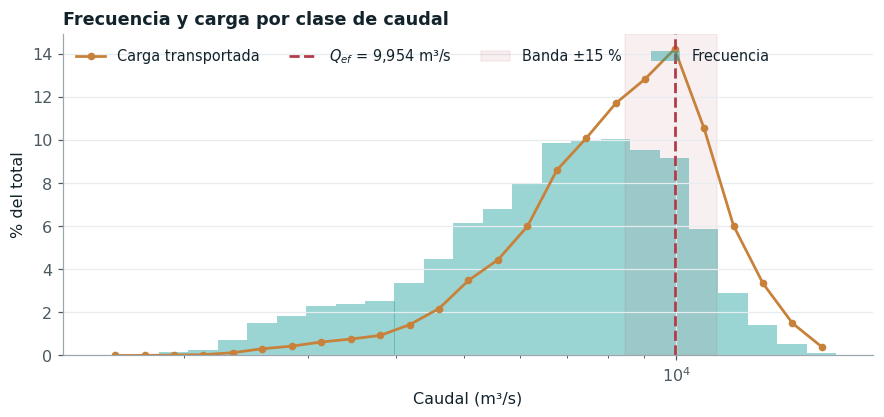

In [7]:
mf = pd.read_csv(DATOS_PROC / "magnitud_frecuencia.csv")
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.bar(mf.q_centro, 100 * mf.frec_rel, width=mf.q_sup - mf.q_inf, color=CAU, alpha=.45, label="Frecuencia")
ax.plot(mf.q_centro, 100 * mf.carga_rel, "-o", color=SED, ms=4, label="Carga transportada")
ax.axvline(par["Q_EF"], color=ALE, ls="--", label=f"$Q_{{ef}}$ = {par['Q_EF']:,.0f} m³/s")
ax.axvspan(*par["LIM"], color=ALE, alpha=.08, label="Banda ±15 %")
ax.set_xscale("log"); ax.set_xlabel("Caudal (m³/s)"); ax.set_ylabel("% del total"); ax.legend(ncol=4, loc="upper left")
ax.set_title("Frecuencia y carga por clase de caudal")
plt.show()

La descarga efectiva de Calamar es {glue:text}`q_ef:,.0f` m³/s, y las ocho ecuaciones
históricas conducen a la misma clase modal, de modo que la posición del máximo depende de la
distribución de frecuencias del caudal y no de la escala de la curva {cite}`nash1994`. La
variable objetivo vale 1 cuando el caudal del día *t* + 15 cae en la banda de ±15 % alrededor
de ese valor, entre {glue:text}`lim_inf:,.0f` y {glue:text}`lim_sup:,.0f` m³/s.

## Variable objetivo

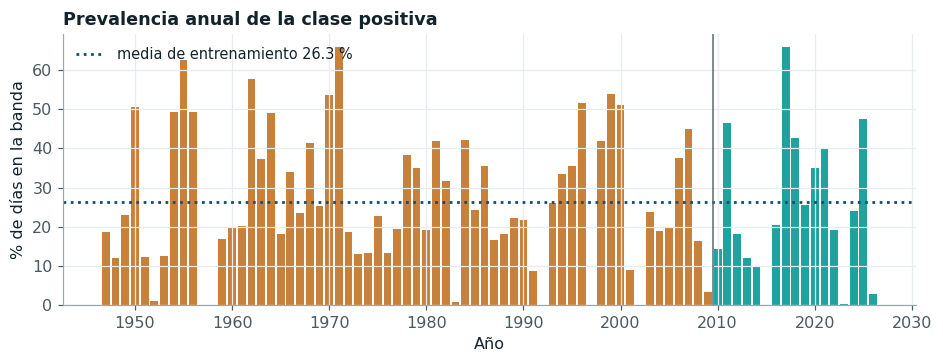

In [8]:
tr = tarea[tarea.fecha < FECHA_CORTE_TEST]; te = tarea[tarea.fecha >= pd.Timestamp(FECHA_CORTE_TEST) + pd.Timedelta(days=30)]
anual = tarea.groupby(tarea.fecha.dt.year).y.mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.bar(anual.index, anual.values, color=[SED if a < 2010 else CAU for a in anual.index])
ax.axhline(100 * tr.y.mean(), color=RIO, ls=":", label=f"media de entrenamiento {100*tr.y.mean():.1f} %")
ax.axvline(2009.5, color=NEU, lw=1)
ax.set_ylabel("% de días en la banda"); ax.set_xlabel("Año"); ax.legend(loc="upper left")
ax.set_title("Prevalencia anual de la clase positiva")
plt.show()
a = tr.groupby(tr.fecha.dt.year).y.mean()
glue("prev_tr", 100 * tr.y.mean(), display=False); glue("prev_te", 100 * te.y.mean(), display=False)
glue("n_pos", int(tr.y.sum()), display=False); glue("n_tr", len(tr), display=False); glue("n_te", len(te), display=False)
glue("anio_min", int(a.idxmin()), display=False); glue("anio_max", int(a.idxmax()), display=False)
glue("prev_max", 100 * a.max(), display=False)

La clase positiva representa el {glue:text}`prev_tr:.1f` % de los {glue:text}`n_tr:,` días de
entrenamiento ({glue:text}`n_pos:,` casos) y el {glue:text}`prev_te:.1f` % de los
{glue:text}`n_te:,` días de prueba. El desbalance global (unos tres días negativos por cada
positivo) es moderado, pero la prevalencia anual varía entre cero en {glue:text}`anio_min`,
año de El Niño, y {glue:text}`prev_max:.0f` % en {glue:text}`anio_max`, año de La Niña. Esa
heterogeneidad tiene dos implicaciones metodológicas. La primera es que el accuracy no
distingue a un buen modelo de la regla trivial, por lo que la métrica de selección es el área
bajo la curva precisión-exhaustividad {cite}`saito2015`. La segunda es que los bloques de
validación deben abarcar años completos, para que cada uno contenga fases hidrológicas
distintas.

## Análisis univariado y bivariado

In [9]:
cols_q = [e for e in EST if e != "arrancaplumas"]
d47m = caudales[caudales.fecha >= INICIO_MODELADO]
desc = d47m[cols_q].describe(percentiles=[.05, .25, .5, .75, .95]).T
desc["asimetría"] = d47m[cols_q].skew(); desc["curtosis"] = d47m[cols_q].kurt()
iqr = desc["75%"] - desc["25%"]
desc["% atípicos (IQR)"] = [100 * ((d47m[c] < desc.loc[c, "25%"] - 1.5 * iqr[c]) | (d47m[c] > desc.loc[c, "75%"] + 1.5 * iqr[c])).mean() for c in cols_q]
desc.index = [NL[c] for c in desc.index]
glue("asim_cal", float(d47m.calamar.skew()), display=False)
desc.drop(columns="count").round(2)

,mean,std,min,5%,25%,50%,75%,95%,max,asimetría,curtosis,% atípicos (IQR)
Calamar,7259.14,2651.52,1520.00,3038.0,5296.00,7119.00,9102.00,11746.0,16913.00,0.26,-0.38,0.26
Coyongal,4988.29,1490.42,874.80,2411.4,3960.00,4977.00,6100.81,7437.0,8648.00,-0.05,-0.60,0.00
El Banco,4117.32,1500.31,911.90,1894.0,3043.22,3945.67,5058.83,6739.0,9681.00,0.55,0.22,0.93
Puerto Salgar,1581.48,770.47,251.28,635.0,1023.00,1424.00,1970.00,3080.0,6595.34,1.20,1.94,3.05
San Roque,497.55,301.78,7.00,89.0,264.00,440.50,689.00,1079.0,1559.00,0.69,-0.05,0.50
Tres Cruces,2329.92,992.35,14.22,802.4,1523.00,2307.00,3063.00,3949.0,5244.00,0.22,-0.57,0.00


Las series de caudal son positivas y sin valores imposibles (no hay ceros ni negativos). Las
estaciones del alto Magdalena presentan asimetría positiva marcada, propia de cuencas de
montaña con crecidas rápidas, mientras que Calamar es casi simétrica (asimetría de
{glue:text}`asim_cal:.2f`) porque la depresión momposina amortigua los picos. Los valores
fuera de 1,5 veces el rango intercuartílico corresponden a crecidas y estiajes reales y se
conservan; los modelos de árboles son invariantes a transformaciones monótonas y en los
demás se aplica escalado estándar dentro del pipeline.

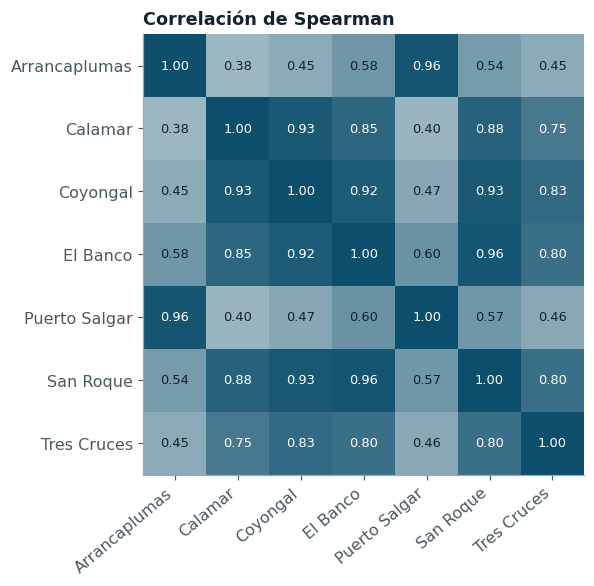

In [10]:
d76 = caudales[(caudales.fecha >= "1976-01-01") & (caudales.fecha < FECHA_CORTE_TEST)]
cm = d76[EST].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.4, 5.2))
im = ax.imshow(cm, cmap=estilo.mapa_div(), vmin=-1, vmax=1)
ax.set_xticks(range(len(EST)), [NL[e] for e in EST], rotation=40, ha="right"); ax.set_yticks(range(len(EST)), [NL[e] for e in EST])
for i in range(len(EST)):
    for j in range(len(EST)):
        ax.text(j, i, f"{cm.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                color="white" if abs(cm.iloc[i, j]) > .6 else "#13232c")
ax.grid(False); ax.set_title("Correlación de Spearman")
plt.show()

In [11]:
from sklearn.feature_selection import mutual_info_classif
from statsmodels.stats.outliers_influence import variance_inflation_factor
cols = par["BASE_COLS"] + par["DOM_COLS"]
Xtr = tr[cols].fillna(tr[cols].median())
mi = mutual_info_classif(Xtr, tr.y.astype(int), random_state=SEED)
pb = [st.pointbiserialr(tr.y, Xtr[c])[0] for c in cols]
mw = [st.mannwhitneyu(Xtr.loc[tr.y == 1, c], Xtr.loc[tr.y == 0, c]) for c in cols]
A = [m.statistic / ((tr.y == 1).sum() * (tr.y == 0).sum()) for m in mw]
from src.stats_tests import benjamini_hochberg
asoc = pd.DataFrame({"variable": cols, "información mutua": mi, "r punto-biserial": pb,
                     "A de Vargha-Delaney": A, "p (BH)": benjamini_hochberg(np.array([m.pvalue for m in mw]))})
Xs = (Xtr - Xtr.mean()) / Xtr.std()
asoc["VIF"] = [variance_inflation_factor(Xs.values, i) for i in range(len(cols))]
asoc = asoc.sort_values("información mutua", ascending=False)
glue("mi_top", asoc.iloc[0].variable, display=False)
glue("n_cols", len(cols), display=False)
glue("vif_altos", int((asoc.VIF > 10).sum()), display=False)
asoc.head(15).round(3)

,variable,información mutua,r punto-biserial,A de Vargha-Delaney,p (BH),VIF
28,calamar_cuad,0.309,0.499,0.890,0.0,93.875
26,dist_qef,0.304,-0.626,0.064,0.0,inf
27,dist_qef_rel,0.304,-0.626,0.064,0.0,inf
0,calamar_lag1,0.298,0.529,0.886,0.0,740.507
1,calamar_lag2,0.286,0.523,0.881,0.0,966.104
2,calamar_lag3,0.276,0.517,0.877,0.0,500.111
9,calamar_media7,0.267,0.513,0.873,0.0,1826.522
3,calamar_lag5,0.255,0.505,0.867,0.0,380.801
4,calamar_lag7,0.241,0.492,0.857,0.0,456.852
29,dist_qef_lag7,0.232,-0.564,0.111,0.0,151.917


La asociación de cada predictor con el objetivo se mide con la información mutua, que capta
relaciones no lineales, junto con la correlación punto-biserial y el tamaño de efecto A, con
control de la tasa de falsos descubrimientos de Benjamini y Hochberg {cite}`benjamini1995` por
tratarse de {glue:text}`n_cols` pruebas simultáneas. La variable más informativa es `{glue:text}`mi_top``, y las variables de
dominio que miden la distancia del caudal actual a la descarga efectiva superan a los rezagos
del caudal en bruto, lo que confirma que la condición de banda no es monótona en el caudal: un
día con caudal muy alto está tan lejos de la banda como uno con caudal muy bajo. El factor de
inflación de varianza supera 10 en {glue:text}`vif_altos` variables, y es infinito para
`dist_qef` y `dist_qef_rel`, que difieren solo en la escala (la segunda es la primera dividida
por $Q_{ef}$); esa redundancia exacta, heredada del Entregable 1, es inocua para los árboles y
la absorbe la regularización en los modelos lineales. El resto de la multicolinealidad es física (rezagos sucesivos de una serie con autocorrelación de 0,999 y estaciones vecinas
sobre el mismo cauce) y no se elimina por selección de variables; se trata con regularización
en los modelos lineales, que es precisamente la segunda corrección solicitada.

## Componente temporal

C:\Users\User\AppData\Local\Temp\ipykernel_7188\3636174615.py:5: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  p_adf = adfuller(s, autolag="AIC")[1]; p_kpss = kpss(s, regression="c", nlags="auto")[1]


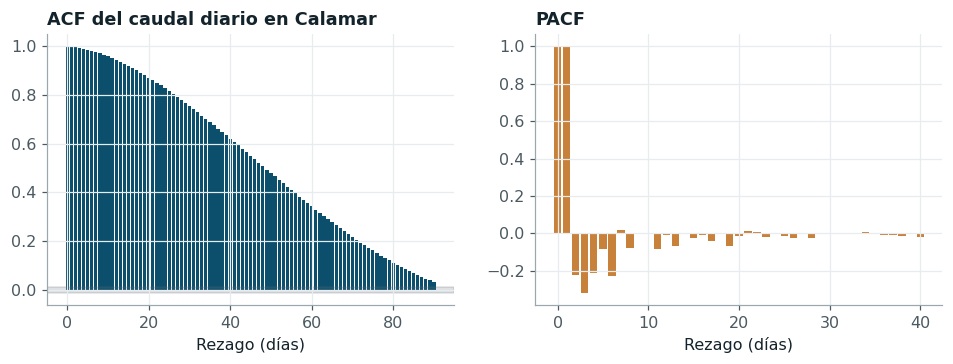

In [12]:
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.tsa.seasonal import STL
s = caudales[(caudales.fecha >= INICIO_MODELADO) & (caudales.fecha < FECHA_CORTE_TEST)].set_index("fecha").calamar
s = s.interpolate(limit=5).dropna()
p_adf = adfuller(s, autolag="AIC")[1]; p_kpss = kpss(s, regression="c", nlags="auto")[1]
ac, pac = acf(s, nlags=90, fft=True), pacf(s, nlags=40)
mens = s.resample("MS").mean().interpolate(limit_direction="both")  # meses sin dato en las décadas tempranas
stl = STL(mens, period=12, robust=True).fit()
glue("p_adf", p_adf, display=False); glue("p_kpss", p_kpss, display=False)
glue("acf1", ac[1], display=False); glue("acf15", ac[15], display=False); glue("acf30", ac[30], display=False)
glue("pacf2", pac[2], display=False)
var_est = 1 - np.var(stl.resid) / np.var(stl.resid + stl.seasonal)
glue("fuerza_est", var_est, display=False)
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio", "agosto", "septiembre", "octubre", "noviembre", "diciembre"]
perfil = stl.seasonal.groupby(stl.seasonal.index.month).mean()
picos = [m for m in perfil.index if perfil[m] >= perfil.get(m - 1, perfil[12]) and perfil[m] >= perfil.get(m + 1, perfil[1])]
picos = sorted(picos, key=lambda m: -perfil[m])[:2]
glue("mes_pico1", MESES[picos[0] - 1], display=False); glue("mes_pico2", MESES[picos[1] - 1], display=False)
glue("mes_min", MESES[int(perfil.idxmin()) - 1], display=False)
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.2))
axs[0].bar(range(91), ac, color=RIO, width=.8); axs[0].set_title("ACF del caudal diario en Calamar")
axs[0].axhspan(-1.96 / np.sqrt(len(s)), 1.96 / np.sqrt(len(s)), color=NEU, alpha=.2); axs[0].set_xlabel("Rezago (días)")
axs[1].bar(range(41), pac, color=SED, width=.8); axs[1].set_title("PACF"); axs[1].set_xlabel("Rezago (días)")
plt.show()

La autocorrelación del caudal diario es {glue:text}`acf1:.3f` a un día, {glue:text}`acf15:.2f`
a quince y {glue:text}`acf30:.2f` a treinta; la autocorrelación parcial a dos días es
{glue:text}`pacf2:.2f`, señal de que la dinámica de corto plazo está dominada por los dos
primeros rezagos y que los siguientes aportan correcciones decrecientes. La prueba ADF rechaza
la raíz unitaria (p = {glue:text}`p_adf:.2g`) y la KPSS no rechaza la estacionariedad
(p = {glue:text}`p_kpss:.2f`); como sus hipótesis nulas son opuestas, la coincidencia respalda
que la serie es estacionaria en nivel alrededor de un ciclo estacional estable.

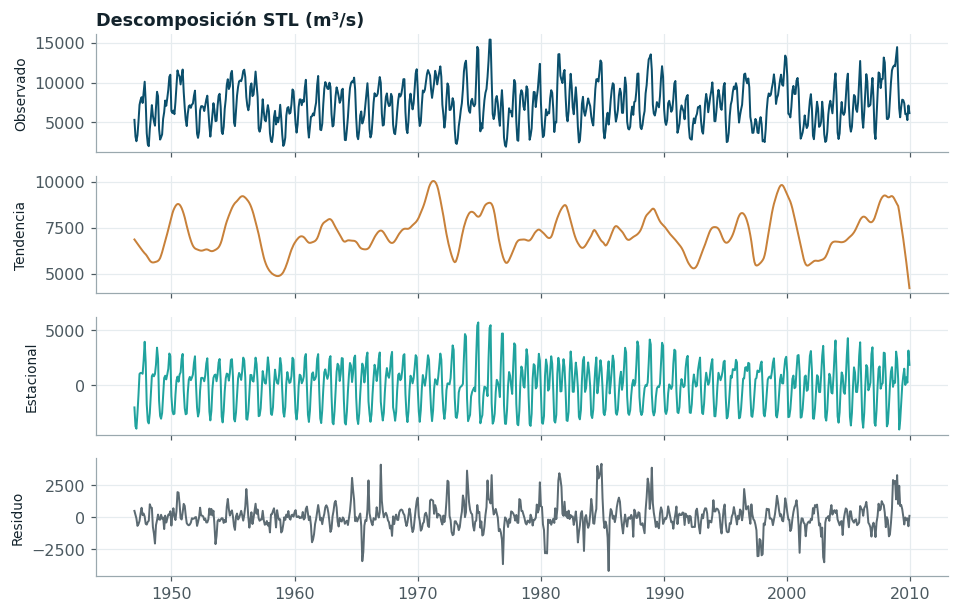

In [13]:
fig, axs = plt.subplots(4, 1, figsize=(10, 6.4), sharex=True)
for ax, (serie, nombre, c) in zip(axs, [(mens, "Observado", RIO), (stl.trend, "Tendencia", SED),
                                        (stl.seasonal, "Estacional", CAU), (stl.resid, "Residuo", NEU)]):
    ax.plot(serie.index, serie.values, color=c, lw=1.3); ax.set_ylabel(nombre, fontsize=9)
axs[0].set_title("Descomposición STL (m³/s)")
plt.show()

La descomposición STL {cite}`cleveland1990` separa una componente estacional bimodal, con
máximo principal en {glue:text}`mes_pico1`, máximo secundario en {glue:text}`mes_pico2` y mínimo
en {glue:text}`mes_min`, de una tendencia que oscila en escala interanual. La fuerza de la estacionalidad, medida como la fracción de la varianza
no tendencial que explica la componente estacional, es {glue:text}`fuerza_est:.2f`. Las
oscilaciones de la tendencia coinciden con la alternancia de El Niño y La Niña documentada para
la cuenca {cite}`restrepo2000` y constituyen la principal fuente de deriva entre periodos, que
se cuantifica a continuación.

In [14]:
def psi(a, b, bins=10):
    q = np.quantile(a, np.linspace(0, 1, bins + 1)); q[0], q[-1] = -np.inf, np.inf
    pa, pb_ = np.histogram(a, q)[0] / len(a), np.histogram(b, q)[0] / len(b)
    pa, pb_ = np.clip(pa, 1e-4, None), np.clip(pb_, 1e-4, None)
    return float(((pa - pb_) * np.log(pa / pb_)).sum())
cq = caudales.set_index("fecha")
p1, p2, p3 = cq["1976":"1992"], cq["1993":"2009"], cq["2010":]
filas = []
for v in ["calamar", "pto_salgar", "el_banco", "tres_cruces", "coyongal", "san_roque"]:
    a, b, c = p1[v].dropna(), p2[v].dropna(), p3[v].dropna()
    filas.append({"variable": v, "media 1976-92": a.mean(), "media 1993-09": b.mean(), "media 2010-26": c.mean(),
                  "PSI 76-92 → 93-09": psi(a, b), "PSI 93-09 → 10-26": psi(b, c),
                  "KS 93-09 vs 10-26": st.ks_2samp(b, c).statistic})
deriva = pd.DataFrame(filas)
ty = tarea.set_index("fecha").y
filas_y = {"variable": "y (prevalencia)", "media 1976-92": ty["1976":"1992"].mean(), "media 1993-09": ty["1993":"2009"].mean(), "media 2010-26": ty["2010":].mean()}
glue("psi_max", float(deriva[["PSI 76-92 → 93-09", "PSI 93-09 → 10-26"]].max().max()), display=False)
glue("psi_tc", float(deriva.set_index("variable").loc["tres_cruces", "PSI 93-09 → 10-26"]), display=False)
glue("psi_coy", float(deriva.set_index("variable").loc["coyongal", "PSI 76-92 → 93-09"]), display=False)
glue("psi_ps", float(deriva.set_index("variable").loc["pto_salgar", "PSI 93-09 → 10-26"]), display=False)
glue("psi_cal", float(deriva.set_index("variable").loc["calamar", "PSI 93-09 → 10-26"]), display=False)
pd.concat([deriva, pd.DataFrame([filas_y])]).round(3)

,variable,media 1976-92,media 1993-09,media 2010-26,PSI 76-92 → 93-09,PSI 93-09 → 10-26,KS 93-09 vs 10-26
0,calamar,7154.156,7334.995,7349.734,0.038,0.023,0.034
1,pto_salgar,1379.514,1409.371,1519.530,0.008,0.038,0.079
2,el_banco,4131.635,4079.978,3931.417,0.109,0.098,0.086
3,tres_cruces,2208.231,2848.888,1877.972,0.494,1.017,0.388
4,coyongal,4788.893,5074.333,5124.394,0.561,0.190,0.135
5,san_roque,481.706,526.155,441.538,0.086,0.144,0.167
0,y (prevalencia),0.229,0.274,0.251,NaN,NaN,NaN


La deriva se cuantifica con el índice de estabilidad poblacional (PSI) y el estadístico de
Kolmogorov-Smirnov entre tres periodos. Con miles de días la prueba KS rechaza casi cualquier
diferencia, por lo que la interpretación se apoya en el PSI: por debajo de 0,1 el desplazamiento
se considera menor, entre 0,1 y 0,25 moderado y por encima de 0,25 severo. El caudal de Calamar
y el objetivo son estables (PSI de {glue:text}`psi_cal:.3f` entre el entrenamiento reciente y la
prueba), y la prevalencia de la clase positiva es prácticamente la misma en ambos periodos, de
modo que no hay desplazamiento de la distribución a priori. Puerto Salgar, la estación
predictora de la tarea principal, también es estable (PSI de {glue:text}`psi_ps:.3f`). Dos
estaciones del bajo Magdalena, en cambio, muestran desplazamientos severos: Coyongal entre las dos mitades del entrenamiento
(PSI = {glue:text}`psi_coy:.2f`) y Tres Cruces entre el entrenamiento y la prueba
(PSI = {glue:text}`psi_tc:.2f`, con una media que pasa de unos 2.850 a 1.880 m³/s). Como el
caudal de Calamar, que integra el aporte de esas estaciones, no cambia en la misma proporción,
el desplazamiento apunta a cambios en la curva de calibración o en la ubicación del sensor y no
a un cambio hidrológico: es una deriva de medición. Ese hallazgo es un argumento adicional a
favor del diseño adoptado, que no usa esas estaciones como predictores de Calamar; en las
tareas adicionales del capítulo 6, donde sí intervienen, la deriva afecta por igual a todos los
modelos comparados.

In [15]:
from src.etl import tiempos_transito
ubic = pd.read_csv(DATOS_PROC / "ubicaciones.csv")
ubic.columns = ["estacion", "codigo", "departamento", "municipio", "lat", "lon", "altitud"]
mapa = {"ARRANCAPLUMAS - AUT": "arrancaplumas", "PUERTO SALGAR - AUT": "pto_salgar", "TRES CRUCES": "tres_cruces",
        "COYONGAL": "coyongal", "EL BANCO - AUT": "el_banco", "SAN ROQUE": "san_roque", "CALAMAR": "calamar"}
ubic["clave"] = ubic.estacion.map(mapa)
ubic["transito"] = ubic.clave.map({**par["TRANSITOS"], "calamar": 0})
g = ubic.dropna(subset=["transito"])
rs = st.spearmanr(g.altitud, g.transito)[0]; rp = st.pearsonr(g.lat, g.transito)[0]
glue("rs_alt", rs, display=False); glue("rp_lat", rp, display=False)
g[["estacion", "municipio", "altitud", "lat", "transito"]].sort_values("transito", ascending=False)

,estacion,municipio,altitud,lat,transito
1,PUERTO SALGAR - AUT,Puerto Salgar,168,5.469667,21
0,ARRANCAPLUMAS - AUT,Guaduas,222,5.202417,20
2,TRES CRUCES,Achí,31,8.703083,16
4,EL BANCO - AUT,El Banco,29,8.992528,12
5,SAN ROQUE,El Banco,24,9.071622,10
3,COYONGAL,Magangué,20,8.915130,7
6,CALAMAR,Calamar,8,10.244042,0


Los tiempos de tránsito de la onda de crecida hacia Calamar, estimados en el Entregable 1 por
correlación cruzada sin usar información geográfica, crecen con la distancia al mar: su
correlación de Spearman con la altitud es {glue:text}`rs_alt:.2f` y la de Pearson con la latitud
es {glue:text}`rp_lat:.2f`. Esa concordancia externa respalda el uso de cada estación desfasada
por su tiempo de tránsito.

## Análisis multivariado

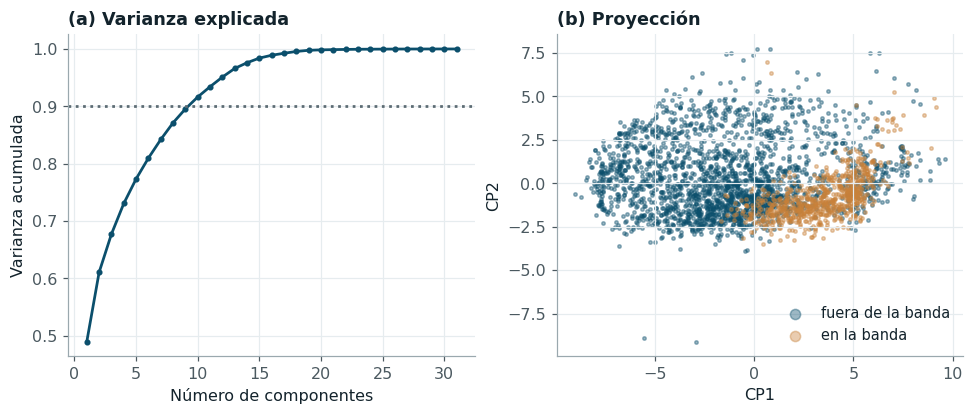

In [16]:
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.covariance import MinCovDet
pca = PCA().fit(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
k90 = int(np.searchsorted(cum, .90) + 1)
Z = pca.transform(Xs)[:, :2]
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.8))
axs[0].plot(range(1, len(cum) + 1), cum, "-o", ms=3, color=RIO); axs[0].axhline(.9, color=NEU, ls=":")
axs[0].set_xlabel("Número de componentes"); axs[0].set_ylabel("Varianza acumulada"); axs[0].set_title("(a) Varianza explicada")
idx = np.random.default_rng(0).choice(len(Z), 3000, replace=False)
for cl, c, n in ((0, RIO, "fuera de la banda"), (1, SED, "en la banda")):
    m = tr.y.values[idx] == cl
    axs[1].scatter(Z[idx][m, 0], Z[idx][m, 1], s=5, alpha=.4, color=c, label=n)
axs[1].set_xlabel("CP1"); axs[1].set_ylabel("CP2"); axs[1].legend(markerscale=3); axs[1].set_title("(b) Proyección")
plt.show()
iso = IsolationForest(random_state=SEED, contamination="auto").fit(Xs)
pct_iso = 100 * (iso.predict(Xs) == -1).mean()
mcd = MinCovDet(random_state=SEED).fit(Xs.iloc[:, :20])
d2 = mcd.mahalanobis(Xs.iloc[:, :20])
pct_mah = 100 * (d2 > st.chi2.ppf(.999, 20)).mean()
marcados = iso.predict(Xs) == -1
q_cal = tr.calamar.values
glue("iso_extremos", 100 * np.mean((q_cal[marcados] > np.quantile(q_cal, .9)) | (q_cal[marcados] < np.quantile(q_cal, .1))), display=False)
glue("k90", k90, display=False); glue("pc1", pca.explained_variance_ratio_[0], display=False)
glue("pct_iso", pct_iso, display=False); glue("pct_mah", pct_mah, display=False)

Las {glue:text}`k90` primeras componentes principales explican el 90 % de la varianza de
{glue:text}`n_cols` predictores, y la primera concentra el {glue:text}`pc1:.0%`, lo que confirma la fuerte
redundancia entre rezagos y estaciones. La proyección en el plano de las dos primeras
componentes muestra que la clase positiva ocupa una franja de la primera componente, la que
resume el nivel general de caudal, con días negativos a ambos lados: una
frontera que ningún clasificador lineal puede trazar sin las variables de distancia a la
descarga efectiva. Isolation Forest marca el {glue:text}`pct_iso:.1f` % de los días como
atípicos multivariados, y el {glue:text}`iso_extremos:.0f` % de ellos corresponde a días con el
caudal de Calamar en el decil superior o inferior: son crecidas y estiajes, eventos
hidrológicamente válidos que se conservan. La distancia de Mahalanobis robusta (determinante de
covarianza mínima sobre las primeras 20 variables, umbral χ² al 99,9 %) marca el
{glue:text}`pct_mah:.1f` %, una proporción incompatible con un umbral del 0,1 %: el resultado no
señala atípicos sino que la distribución conjunta, con colas pesadas y relaciones no lineales
entre rezagos, se aparta de la normalidad multivariada que ese umbral supone. Por esa razón la
detección de atípicos se apoya en Isolation Forest, que no requiere ese supuesto.

## Auditoría de fuga de datos

In [17]:
from sklearn.metrics import roc_auc_score
fuga = pd.DataFrame([{"variable": c, "AUC": max(roc_auc_score(tr.y, Xtr[c]), 1 - roc_auc_score(tr.y, Xtr[c]))}
                     for c in cols]).sort_values("AUC", ascending=False)
glue("auc_max", float(fuga.AUC.max()), display=False)
fuga.to_csv(DATOS_PROC / "fuga.csv", index=False)
fuga.head(8).round(3)

,variable,AUC
27,dist_qef_rel,0.936
26,dist_qef,0.936
28,calamar_cuad,0.890
29,dist_qef_lag7,0.889
0,calamar_lag1,0.886
1,calamar_lag2,0.881
2,calamar_lag3,0.877
9,calamar_media7,0.873


Todas las variables se construyen con información hasta el día *t* y el objetivo se ubica en
*t* + 15, de modo que estarían disponibles en el momento de la predicción. El área bajo la
curva ROC de cada predictor por separado alcanza un máximo de {glue:text}`auc_max:.3f`, por
debajo del umbral de alerta de 0,95; las variables más altas miden la cercanía del caudal
actual a la banda, información legítima cuyo poder decae con el horizonte. No hay
identificadores ni entidades repetidas entre particiones, porque la partición es cronológica y
la única entidad es la red de estaciones.

## Preprocesamiento derivado del EDA

| Decisión | Hallazgo que la motiva |
|---|---|
| Predictores restringidos a Calamar y Puerto Salgar; modelado desde 1947 | Faltantes estructurales anteriores a la instalación de la red ({numref}`fig-cobertura`) y mínimo de 20.000 observaciones |
| Imputación por mediana dentro del pipeline, con análisis de sensibilidad | Huecos residuales MAR, con incidencia baja en Calamar y Puerto Salgar |
| Escalado estándar; sin transformación logarítmica | Calamar casi simétrica; atípicos válidos |
| Variables de distancia a $Q_{ef}$ | Objetivo no monótono en el caudal ({numref}`fig-pca`) |
| Puerto Salgar desfasada 21 días (su tiempo de tránsito) | Correlación cruzada verificada con la geografía |
| Armónicos anual y semianual | Estacionalidad bimodal ({numref}`fig-stl`) |
| Regularización L1/L2 en modelos lineales | VIF > 10 por colinealidad física |
| Bloques externos de dos años y separación de 30 días | ACF de 0,92 a 15 días; heterogeneidad interanual |
| PR-AUC como métrica principal | Clase positiva del 25 % y prevalencia anual variable |

## Corrección 2 y 3: modelo base con regularización ajustada e intervalos por bloques

In [18]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import average_precision_score, f1_score
from src.models import construir_pipeline
from src.stats_tests import bootstrap_bloques, longitud_bloque
from src.experiment import cargar_datos
D = cargar_datos()
base = construir_pipeline("clf", "logistica", {"C": 1.0, "penalty": "l2"}, "balanced")
grid = GridSearchCV(base, {"modelo__C": np.logspace(-3, 2, 11), "modelo__penalty": ["l1", "l2"]},
                    scoring="average_precision", cv=TimeSeriesSplit(5, gap=30), n_jobs=4).fit(D.X, D.y_clf)
C_opt, pen = grid.best_params_["modelo__C"], grid.best_params_["modelo__penalty"]
p_ajust = grid.best_estimator_.predict_proba(D.X_test)[:, 1]
p_def = base.fit(D.X, D.y_clf).predict_proba(D.X_test)[:, 1]
y = D.y_clf_test.values
pers = D.X_test["dist_qef"].values <= 0.15 * par["Q_EF"]
pers = pers.astype(float)
L = longitud_bloque(y.astype(float))
filas = []
for nombre, s in (("Persistencia", pers), ("Logística C = 1 (Entregable 1)", p_def), (f"Logística C = {C_opt:.3g}, {pen}", p_ajust)):
    ic_b = bootstrap_bloques(average_precision_score, y, s, media_bloque=L, n_boot=1000)
    rng = np.random.default_rng(SEED); iid = []
    for _ in range(1000):
        i = rng.integers(0, len(y), len(y)); iid.append(average_precision_score(y[i], s[i]))
    filas.append({"modelo": nombre, "PR-AUC": ic_b["estimacion"],
                  "IC 95 % bloques (BCa)": f"[{ic_b['ic_inf']:.3f}; {ic_b['ic_sup']:.3f}]",
                  "IC 95 % filas i.i.d.": f"[{np.percentile(iid, 2.5):.3f}; {np.percentile(iid, 97.5):.3f}]",
                  "ancho bloques / ancho i.i.d.": (ic_b["ic_sup"] - ic_b["ic_inf"]) / (np.percentile(iid, 97.5) - np.percentile(iid, 2.5)),
                  "F1": f1_score(y, (s >= .5).astype(int))})
base_tab = pd.DataFrame(filas)
glue("c_opt", C_opt, display=False); glue("pen", pen, display=False); glue("L_bloque", L, display=False)
glue("ratio_ic", float(base_tab["ancho bloques / ancho i.i.d."].iloc[-1]), display=False)
glue("ap_base", float(base_tab["PR-AUC"].iloc[-1]), display=False)
base_tab.round(3)

,modelo,PR-AUC,IC 95 % bloques (BCa),IC 95 % filas i.i.d.,ancho bloques / ancho i.i.d.,F1
0,Persistencia,0.652,[0.536; 0.750],[0.630; 0.676],4.594,0.770
1,Logística C = 1 (Entregable 1),0.881,[0.778; 0.940],[0.861; 0.901],4.026,0.815
2,"Logística C = 1, l2",0.881,[0.778; 0.940],[0.861; 0.901],4.026,0.815


El parámetro de regularización se elige ahora por búsqueda en rejilla con validación
cronológica de cinco pliegues y separación de 30 días sobre el entrenamiento, entre once
valores de C de $10^{-3}$ a $10^{2}$ y las penalizaciones L1 y L2. El óptimo es
C = {glue:text}`c_opt:.3g` con penalización {glue:text}`pen`, que con el diseño corregido coincide
con el valor por defecto empleado en el Entregable 1: la diferencia está en que ahora la
elección se sustenta en la validación y no en la omisión del ajuste. En el capítulo siguiente
este ajuste se generaliza a la validación anidada de los 140 modelos. Los intervalos de confianza se
recalculan con bootstrap estacionario {cite}`politis1994`, cuya longitud media de bloque
({glue:text}`L_bloque` días) se elige con el criterio de Politis y White {cite}`politis2004`, y
con corrección BCa estimada mediante un jackknife que elimina bloques completos. El intervalo
por bloques es {glue:text}`ratio_ic:.1f` veces más ancho que el que remuestrea filas
independientes: el informe original subestimaba la incertidumbre en esa proporción, exactamente
el problema que señaló la retroalimentación.

In [19]:
# Sensibilidad a la imputación en los 12 bloques externos
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
res = []
for nombre, imp in (("mediana", SimpleImputer(strategy="median")),
                    ("mediana + indicador", SimpleImputer(strategy="median", add_indicator=True)),
                    ("iterativa (condicional)", IterativeImputer(max_iter=10, random_state=SEED))):
    for p in D.pliegues:
        pipe = Pipeline([("imp", imp), ("esc", StandardScaler()),
                         ("m", LogisticRegression(C=C_opt, penalty=pen, solver="liblinear", class_weight="balanced", max_iter=5000))])
        pipe.fit(D.X.iloc[p["train"]], D.y_clf.iloc[p["train"]])
        res.append({"imputación": nombre, "pliegue": p["pliegue"],
                    "pr_auc": average_precision_score(D.y_clf.iloc[p["test"]], pipe.predict_proba(D.X.iloc[p["test"]])[:, 1])})
res = pd.DataFrame(res)
tab_imp = res.groupby("imputación").pr_auc.agg(["mean", "std"])
w = st.wilcoxon(res[res["imputación"] == "mediana"].pr_auc.values, res[res["imputación"] == "iterativa (condicional)"].pr_auc.values)
glue("p_imp", w.pvalue, display=False)
glue("imp_lectura", "no permite distinguirlas" if w.pvalue >= 0.05 else "las distingue", display=False)
glue("dif_imp", float(tab_imp.loc["iterativa (condicional)", "mean"] - tab_imp.loc["mediana", "mean"]), display=False)
tab_imp.round(4)

,mean,std
imputación,,
iterativa (condicional),0.8386,0.1363
mediana,0.8406,0.1350
mediana + indicador,0.8388,0.1358


La última verificación compara, en los doce bloques externos, la imputación por mediana con
una imputación iterativa que condiciona cada variable a las demás, la estrategia apropiada bajo
un mecanismo MAR, y con la mediana acompañada de indicadores de faltante. La diferencia media de
PR-AUC entre la imputación iterativa y la mediana es {glue:text}`dif_imp:+.4f`, y la prueba de
Wilcoxon {glue:text}`imp_lectura` (p = {glue:text}`p_imp:.2f`). Con faltantes residuales de esta
magnitud la elección del imputador no cambia las conclusiones, y se conserva la mediana por su
menor costo dentro de los 140 modelos.